# Laboratory 4, Part A - Simple Linear Regression (Salary vs Experience)

**Course:** Introduction to Artificial Intelligence (AI-101L)   **Student:** Arham Rizwan

**Question:** can years of experience predict salary with a straight line?
A simple linear regression fits  `Salary = intercept + slope x YearsExperience`
by choosing the line with the smallest sum of squared errors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("data/Salary_dataset.csv")
print("Shape:", df.shape, "| missing values:", int(df.isnull().sum().sum()))
display(df.head())
display(df.describe().round(2))

Shape: (30, 2) | missing values: 0


,YearsExperience,Salary
0,1.2,39344
1,1.4,46206
2,1.6,37732
3,2.1,43526
4,2.3,39892


,YearsExperience,Salary
count,30.00,30.00
mean,5.41,76004.00
std,2.84,27414.43
min,1.20,37732.00
25%,3.30,56721.75
50%,4.80,65238.00
75%,7.80,100545.75
max,10.60,122392.00


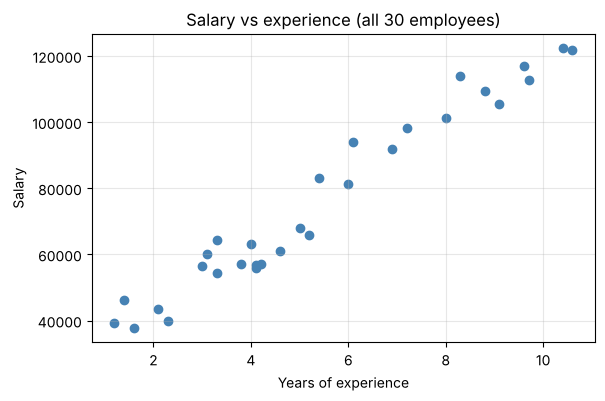

Correlation: 0.978


In [2]:
plt.figure(figsize=(6.5, 4))
plt.scatter(df["YearsExperience"], df["Salary"], color="steelblue")
plt.xlabel("Years of experience")
plt.ylabel("Salary")
plt.title("Salary vs experience (all 30 employees)")
plt.grid(alpha=0.3)
plt.show()

print("Correlation:", round(df["YearsExperience"].corr(df["Salary"]), 3))

## Train / test split

Eighty percent of the rows train the model; twenty percent are held back to test it on data it has not seen.

In [3]:
X = df[["YearsExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), "| test rows:", len(X_test))

model = LinearRegression().fit(X_train, y_train)
slope = model.coef_[0]
intercept = model.intercept_
print(f"Salary = {intercept:,.0f} + {slope:,.0f} x YearsExperience")
print(f"Each extra year of experience adds about {slope:,.0f} to the predicted salary.")

Training rows: 24 | test rows: 6
Salary = 24,380 + 9,424 x YearsExperience
Each extra year of experience adds about 9,424 to the predicted salary.


In [4]:
predicted = model.predict(X_test)
comparison = pd.DataFrame({
    "YearsExperience": X_test["YearsExperience"].values,
    "Actual": y_test.values,
    "Predicted": predicted.round(0),
})
comparison["Error"] = (comparison["Actual"] - comparison["Predicted"]).round(0)
comparison

,YearsExperience,Actual,Predicted,Error
0,9.7,112636,115791.0,-3155.0
1,5.0,67939,71499.0,-3560.0
2,8.3,113813,102598.0,11215.0
3,5.4,83089,75269.0,7820.0
4,3.3,64446,55479.0,8967.0
5,3.8,57190,60191.0,-3001.0


## Metrics on the test set

- **MAE** - average absolute error, in salary units.
- **MSE** - average squared error (punishes big misses).
- **RMSE** - square root of MSE, back in salary units.
- **R squared** - share of the variation in salary the line explains (1 is perfect, 0 is no better than predicting the mean).

In [5]:
mae = mean_absolute_error(y_test, predicted)
mse = mean_squared_error(y_test, predicted)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predicted)

print(f"MAE      : {mae:,.0f}")
print(f"MSE      : {mse:,.0f}")
print(f"RMSE     : {rmse:,.0f}")
print(f"R squared: {r2:.3f}")
print()
print(f"Train R squared: {model.score(X_train, y_train):.3f}   Test R squared: {r2:.3f}")

MAE      : 6,286
MSE      : 49,830,097
RMSE     : 7,059
R squared: 0.902

Train R squared: 0.965   Test R squared: 0.902


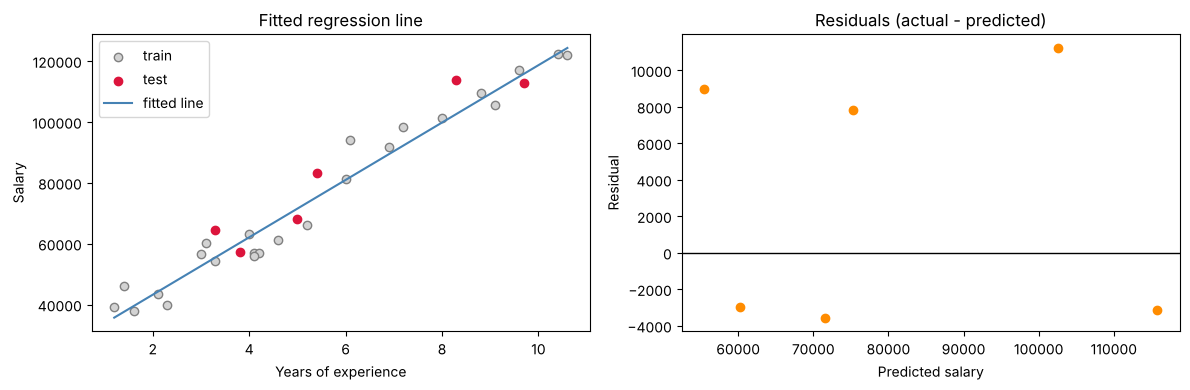

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X_train, y_train, label="train", color="lightgray", edgecolor="gray")
axes[0].scatter(X_test, y_test, label="test", color="crimson")
line_x = np.linspace(df["YearsExperience"].min(), df["YearsExperience"].max(), 100).reshape(-1, 1)
axes[0].plot(line_x, model.predict(pd.DataFrame(line_x, columns=["YearsExperience"])), color="steelblue", label="fitted line")
axes[0].set(title="Fitted regression line", xlabel="Years of experience", ylabel="Salary")
axes[0].legend()

residuals = y_test.values - predicted
axes[1].scatter(predicted, residuals, color="darkorange")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(title="Residuals (actual - predicted)", xlabel="Predicted salary", ylabel="Residual")

plt.tight_layout()
plt.show()

## Checking sklearn against the maths

For one feature the best-fit line has a closed form: slope = covariance(x, y) / variance(x), and the line passes through the mean point.

In [7]:
xt = X_train["YearsExperience"].values
yt = y_train.values
manual_slope = np.cov(xt, yt, bias=True)[0, 1] / np.var(xt)
manual_intercept = yt.mean() - manual_slope * xt.mean()

print(f"By hand : slope {manual_slope:,.2f}  intercept {manual_intercept:,.2f}")
print(f"sklearn : slope {slope:,.2f}  intercept {intercept:,.2f}")
print("Match   :", bool(np.isclose(manual_slope, slope) and np.isclose(manual_intercept, intercept)))

By hand : slope 9,423.82  intercept 24,380.20
sklearn : slope 9,423.82  intercept 24,380.20
Match   : True


In [8]:
# With only 6 test rows one split is a noisy verdict, so check with 5-fold cross-validation too.
# The rows are sorted by experience, so the folds MUST be shuffled; otherwise each fold would be
# one narrow slice of the data and the score would be meaningless.
folds = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(LinearRegression(), X, y, cv=folds, scoring="r2")
print("5-fold R squared per fold:", scores.round(3))
print("Mean:", round(scores.mean(), 3), "| spread (std):", round(scores.std(), 3))

5-fold R squared per fold: [0.902 0.968 0.916 0.982 0.843]
Mean: 0.922 | spread (std): 0.05


## Takeaways

The relationship is close to a straight line, so a simple linear model describes it well. Only 30
employees exist in the data and just 6 land in the test set, so any single score should be read as an
estimate, which is why cross-validation is shown as well. The model also says nothing about *why*
salaries rise: it only describes the pattern in this sample, and it should not be trusted far
outside the observed experience range.